# 3.  Codificación de variables

Conjunto de datos: titanic (incluido en seaborn)

Este conjunto de datos es excelente para trabajar con variables categóricas.

In [1]:
# Importar librerías necesarias
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [2]:
# Cargar el conjunto de datos
data = sns.load_dataset('titanic')

In [3]:
# Visualizar las primeras filas
print("Conjunto de datos Titanic:")
data.head()

Conjunto de datos Titanic:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [4]:
# Seleccionar columnas categóricas
categorical_cols = ['sex', 'embarked', 'class']

In [5]:
# Codificar con LabelEncoder
label_encoder = LabelEncoder()
data['sex_label'] = label_encoder.fit_transform(data['sex'])

In [6]:
# Codificar con OneHotEncoder
onehot_encoder = pd.get_dummies(data['embarked'], prefix='embarked')

In [7]:
# Combinar con el conjunto original
data = pd.concat([data, onehot_encoder], axis=1)

# Ejercicios
Contesta las siguientes preguntas. Para cada pregunta, deberás escribir código que demostrará cómo llegaste al resultado. Crea gráficas en donde veas correcto.

### 1. ¿Qué diferencias encuentras entre LabelEncoder y OneHotEncoder?

In [8]:
# Demostración del comportamiento de ambos encoders
print("--- Demostración con LabelEncoder ---")
print(data[['sex', 'sex_label']].head())

print("\n--- Demostración con OneHotEncoder ---")
ohe_example = OneHotEncoder(sparse_output=False)
sex_ohe = ohe_example.fit_transform(data[['sex']])
df_sex_ohe = pd.DataFrame(sex_ohe, columns=ohe_example.get_feature_names_out(['sex']))
print(df_sex_ohe.head())

--- Demostración con LabelEncoder ---
      sex  sex_label
0    male          1
1  female          0
2  female          0
3  female          0
4    male          1

--- Demostración con OneHotEncoder ---
   sex_female  sex_male
0         0.0       1.0
1         1.0       0.0
2         1.0       0.0
3         1.0       0.0
4         0.0       1.0


LabelEncoder: Convierte texto a enteros simples ($0, 1, 2, ...) en una sola columna. Se usa para variables ordinales (con jerarquía) o etiquetas de salida (target).   OneHotEncoder: Crea una nueva columna binaria (0 o 1) para cada categoría única. Evita asumir un orden matemático donde no lo hay.

### 2. Crea una gráfica de barras comparando las frecuencias de 'sex' antes y después de la codificación con LabelEncoder.

C:\Users\PC\AppData\Local\Temp\ipykernel_31172\1443345025.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex', data=data, ax=axes[0], palette='Set2')
C:\Users\PC\AppData\Local\Temp\ipykernel_31172\1443345025.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='sex_label', data=data, ax=axes[1], palette='Set2')


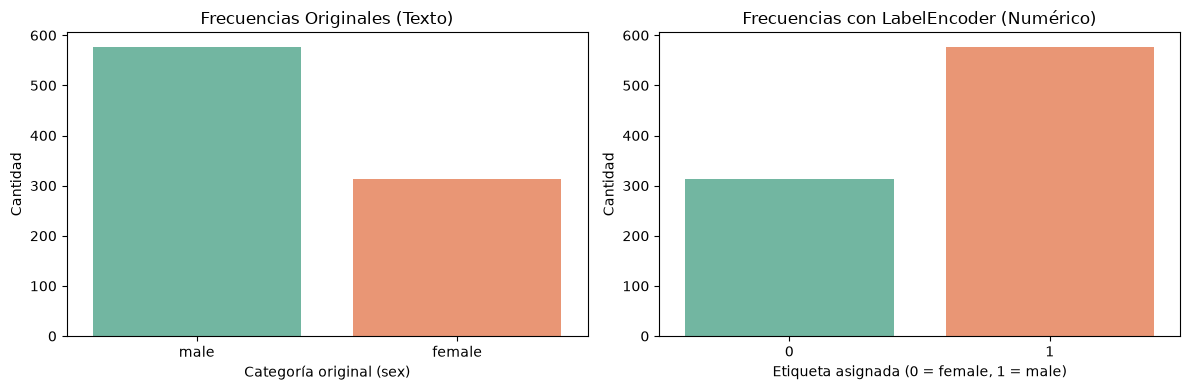

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfica 1: Antes de la codificación (texto)
sns.countplot(x='sex', data=data, ax=axes[0], palette='Set2')
axes[0].set_title('Frecuencias Originales (Texto)')
axes[0].set_xlabel('Categoría original (sex)')
axes[0].set_ylabel('Cantidad')

# Gráfica 2: Después de la codificación (números)
sns.countplot(x='sex_label', data=data, ax=axes[1], palette='Set2')
axes[1].set_title('Frecuencias con LabelEncoder (Numérico)')
axes[1].set_xlabel('Etiqueta asignada (0 = female, 1 = male)')
axes[1].set_ylabel('Cantidad')

plt.tight_layout()
plt.show()

plt.subplots(1, 2, ...): Crea un lienzo con dos subgráficas lado a lado.

sns.countplot(...): Cuenta la cantidad de apariciones de cada categoría.

Resultado: Observarás que la altura de las barras es idéntica; lo único que cambia es el eje X, pasando de palabras ('male', 'female') a números (0, 1).

### 3. Utiliza OneHotEncoder para codificar la columna 'class'. ¿Qué ventajas tiene este enfoque frente a LabelEncoder?

In [10]:
# Aplicar OneHotEncoder a la columna 'class'
ohe_class = OneHotEncoder(sparse_output=False)
class_encoded = ohe_class.fit_transform(data[['class']])

# Crear DataFrame con los nombres de las clases ('First', 'Second', 'Third')
df_class_ohe = pd.DataFrame(
    class_encoded, 
    columns=ohe_class.get_feature_names_out(['class'])
)

df_class_ohe.head()

,class_First,class_Second,class_Third
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,1.0,0.0,0.0
4,0.0,0.0,1.0


ohe_class.fit_transform(data[['class']]): Genera 3 columnas binarias: class_First, class_Second y class_Third.Ventaja clave: Evita que el modelo de Machine Learning interprete erróneamente un orden de importancia numérico (por ejemplo, si usáramos LabelEncoder, asignaría $0, 1, 2$, haciendo que el algoritmo piense que Third (2) vale el doble que Second (1)).

### 4. Si quisieras aplicar un modelo de aprendizaje automático, ¿qué tipo de codificación elegirías para las variables categóricas? Explica tu respuesta.

In [ ]:
# Respuesta explicativa:
"""
La elección de la codificación depende de la naturaleza de cada variable categórica:

1. Para variables NOMINALES (sin orden implícito, ej. 'sex' o 'embarked'):
   - Elección: OneHotEncoder.
   - Razón: Evita que el modelo cree relaciones falsas de orden jerárquico o distancia numérica entre categorías independientes.

2. Para variables ORDINALES (con jerarquía o nivel implícito, ej. 'class' [First > Second > Third]):
   - Elección: OrdinalEncoder (o LabelEncoder en su defecto).
   - Razón: Permite conservar el orden natural entre las categorías mediante valores numéricos (0 < 1 < 2) sin necesidad de multiplicar innecesariamente el número de columnas.

3. Para variables de ALTA CARDINALIDAD (muchas categorías distintas, ej. 'ciudad' o 'código postal'):
   - Elección: Target Encoding o Frequency Encoding.
   - Razón: Evita la "maldición de la dimensionalidad" que generaría OneHotEncoder con cientos de columnas nuevas.
"""